# Setup

In [1]:
# Standard library
import json
from pathlib import Path
from unittest.mock import patch

# Data and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Markdown, display

# Reusable numerical, workflow and presentation tools
from agentic_ts import module01_forecasting as numerical
from agentic_ts import module01_workflow as workflow
from agentic_ts.module01_assets import PublicationAssets

This code imports the libraries required to establish an environment for time-series forecasting, data manipulation, and advanced visualization.

The dependencies are organized into three functional groups:

*   **Standard Library:** Provides tools for file system path management via `pathlib`, JSON data serialization through `json`, and object mocking capabilities using `unittest.mock.patch`.
*   **Data Science and Visualization:** Uses `numpy` for numerical computing and `pandas` for tabular data manipulation. The visualization stack relies on `matplotlib` to generate plots, specifically importing advanced shape tools like `FancyBboxPatch` and `FancyArrowPatch` for custom drawing. Additionally, `IPython.display` is included to render Markdown content within an interactive notebook interface.
*   **Project-Specific Modules:** Integrates a local package named `agentic_ts`, which contains the primary logic for the intended task. This includes specialized modules for forecasting mathematics (`numerical`), process orchestration (`workflow`), and managing assets related to publication (`PublicationAssets`).

In [2]:
class CFG:
    root = Path.cwd()
    data_folder = root / "data" / "module01"
    example_folder = root / "examples" / "module01"
    graph_folder = root / "graphs"
    run_mode = "replay"
    img_dim1 = 20
    img_dim2 = 10
    publication_scale = 0.65
    export_dpi = 180
    table_fontsize = 13
    table_decimals = 2
    table_header_color = "#25455d"
    table_alternate_color = "#eaf0f4"
    table_wrap_chars = 100
    table_line_height = 0.22
    table_min_height = 1.5
    SEED = 42
    colors = {"history": "#4C72B0", "actual": "#222222",
              "forecast": "#55A868", "baseline": "#8172B3"}

plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (CFG.img_dim1, CFG.img_dim2)
np.random.seed(CFG.SEED)
pd.options.display.float_format = "{:.2f}".format
assert (CFG.root / "pyproject.toml").is_file(), "Run from the repository root"
assert CFG.run_mode == "replay"
capture = json.loads((CFG.example_folder / "recorded_run.json").read_text())
print("Mode:", CFG.run_mode, "| Recorded model:", capture["model_identity"]["name"])
print("Numerical versions:", numerical.versions())

Mode: replay | Recorded model: qwen3-coder-next:q4_K_M
Numerical versions: {'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.15.3', 'statsmodels': '0.14.6'}


This code initializes global configuration settings, configures the visualization and numerical environments, and validates that the execution environment meets specific requirements for a "replay" workflow.

The configuration is managed through a `CFG` class and several constant variables:

*   **Path Management:** It defines directory structures for data, examples, and graphs relative to the current working directory. 
*   **Visualization Parameters:** A set of constants controls the aesthetics of generated outputs, including figure dimensions, export resolution (DPI), font sizes, table styling (colors, line height, and wrapping), and a specific color palette for time-series elements such as historical data, actual values, forecasts, and baselines.
*   **Execution Control:** The `run_mode` is set to `"replay"`, indicating that the subsequent logic is intended to reproduce a previous session rather than perform new computations.

The environment is then standardized using the following settings:

*   **Plotting:** It applies the `seaborn-v0_8` style to `matplotlib` and sets default figure sizes based on the configuration.
*   **Reproducibility and Formatting:** It sets a fixed seed for `numpy` random number generation to ensure consistent results and configures `pandas` to display floating-point numbers with two decimal places.

Before proceeding, the code performs two mandatory checks via assertions:

1.  It verifies that the script is being executed from the repository root by checking for the existence of a `pyproject.toml` file.
2.  It enforces that the `run_mode` is strictly set to `"replay"`.

Finally, the code loads a JSON file named `recorded_run.json` from the example folder. This file serves as the input for the replay process, providing metadata about a previously recorded execution. The script outputs the current run mode, the name of the model identified within that JSON data, and the version information of the imported `numerical` module.

# Utils

In [3]:
assets = PublicationAssets(CFG, source_hash=capture["frozen_hash"])


def save_graph(fig, section, cell_id, caption):
    assets.save(fig, "graph", section, cell_id, caption)


def show_table(blocks, section, cell_id, caption):
    assets.table(blocks, section, cell_id, caption)

This code initializes an asset management system designed to handle publication-quality outputs and defines helper functions to standardize how graphs and tables are processed.

The `PublicationAssets` object, named `assets`, is instantiated using the global configuration (`CFG`) and a hash (`capture["frozen_hash"]`) retrieved from the previously loaded JSON data. This hash likely serves to ensure that any generated or retrieved assets are cryptographically linked to the specific version of the data being replayed, maintaining reproducibility.

Two helper functions provide a consistent interface for managing visual outputs:

*   **`save_graph(fig, section, cell_id, caption)`**: This function takes a figure object and metadata—including its logical section, a unique cell identifier, and a descriptive caption—and uses the asset manager to persist it as a graph.
*   **`show_table(blocks, section, cell_id, caption)`**: This function takes data blocks and corresponding metadata (section, cell ID, and caption) and uses the asset manager to render or process the table.

While the specific storage location or rendering mechanism of these functions cannot be determined without the `PublicationAssets` source code, they are designed to automate the organization and labeling of visual assets based on their context within a document or notebook.

In [4]:
def print_report(label, report):
    parts = [f"**{label}**"]
    for name in ("selection", "evaluation", "limitation"):
        claim = report[name]
        parts.append(f"**{name.capitalize()}:** {claim['text']}\n\n"
                     f"Evidence IDs: `{', '.join(claim['evidence_ids'])}`")
    display(Markdown("\n\n".join(parts)))


def print_brief(brief):
    for item in brief["candidates"]:
        display(Markdown(f"**{item['model_id']}:** {item['claim']['text']}\n\n"
                         f"Evidence IDs: `{', '.join(item['claim']['evidence_ids'])}`"))
    display(Markdown("**Limitation:** " + brief["limitation"]["text"]))

These functions provide standardized Markdown rendering for structured diagnostic or summary reports, likely used to present results from an automated analysis system. Both functions rely on specific dictionary structures where textual "claims" are paired with lists of "evidence IDs."

**`print_report(label, report)`**
This function renders a comprehensive multi-section report. It expects a `report` dictionary containing three mandatory keys: `"selection"`, `"evaluation"`, and `"limitation"`. 

The logic follows these steps:
*   It initializes the output with a bolded `label`.
*   It iterates through the three required categories, capitalizing each key to serve as a header.
*   For each category, it extracts and formats a textual claim and a comma-separated list of associated evidence identifiers.
*   The entire formatted string is then displayed as rendered Markdown.

**`print_brief(brief)`**
This function renders a condensed summary, focused on comparing multiple model candidates. It expects a `brief` dictionary with two primary components: `"candidates"` and `"limitation"`.

The logic follows these steps:
*   It iterates through the list of candidate models, displaying each model's ID alongside its specific claim and the corresponding evidence IDs in Markdown format.
*   After processing all candidates, it appends a final "Limitation" section using the text provided in the `brief["limitation"]` field.

# Why chain a forecasting workflow?

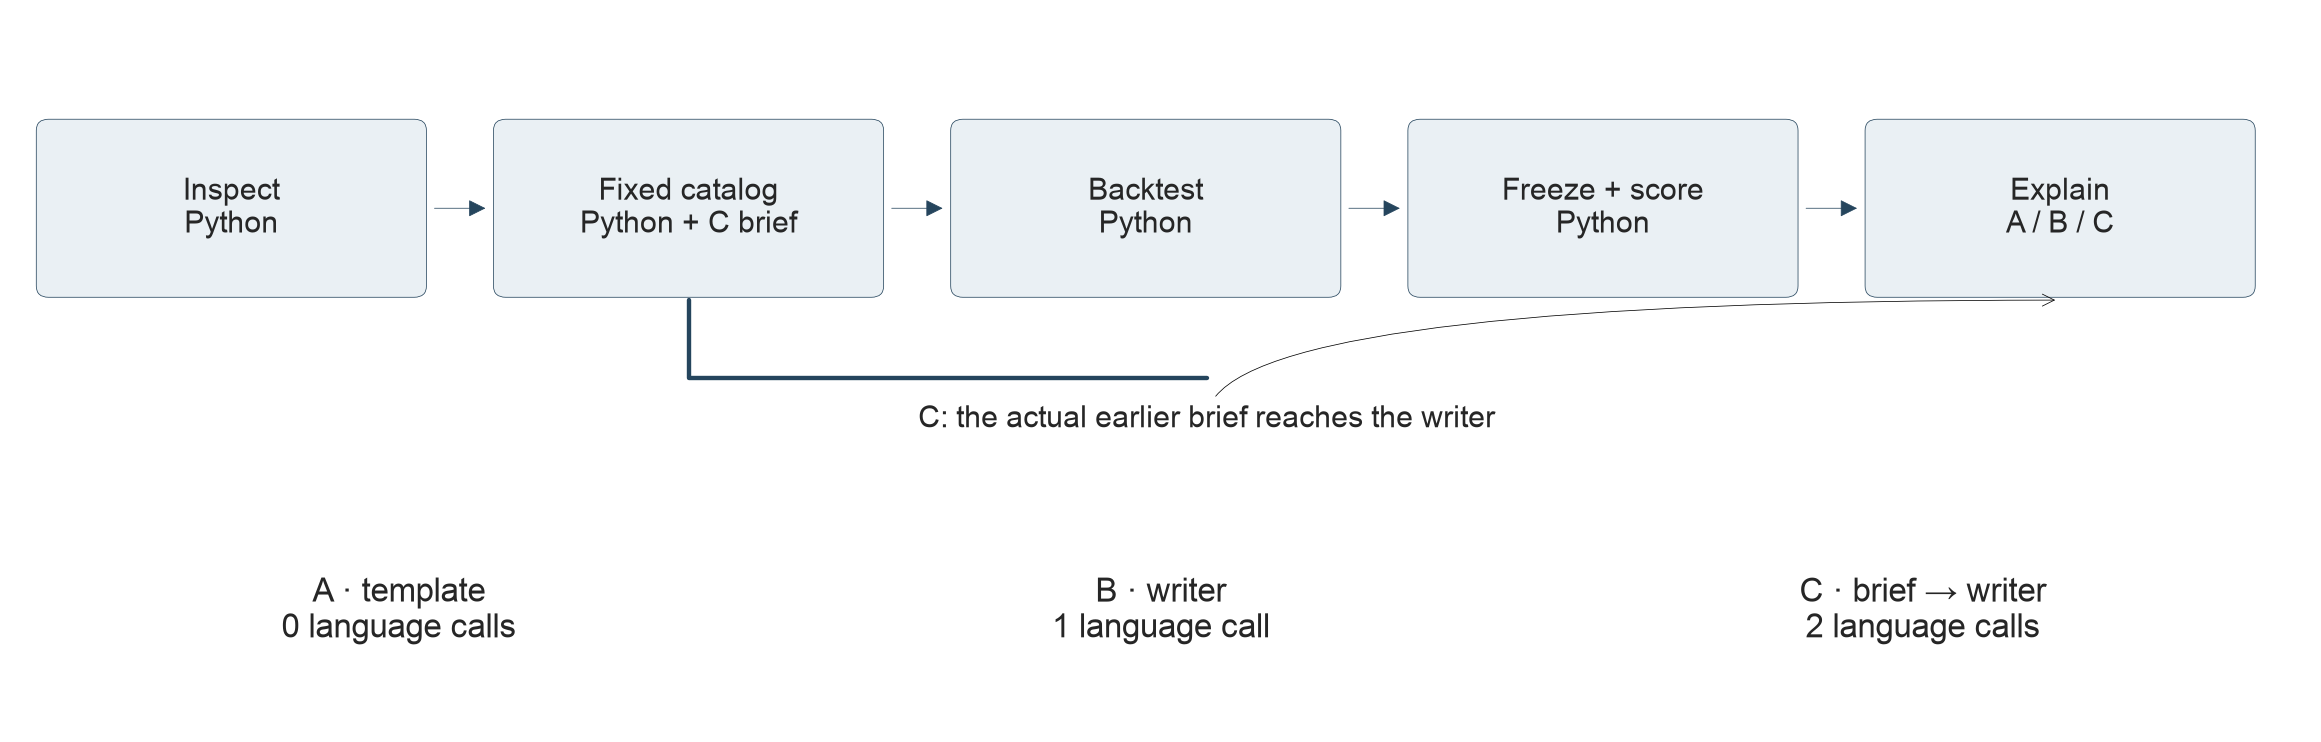

In [5]:
fig, ax = plt.subplots(figsize=(CFG.img_dim1 * CFG.publication_scale,
                                CFG.img_dim2 * CFG.publication_scale * 0.65))
ax.set(xlim=(0, 15), ylim=(0, 5))
ax.axis("off")
labels = ["Inspect\nPython", "Fixed catalog\nPython + C brief", "Backtest\nPython",
          "Freeze + score\nPython", "Explain\nA / B / C"]
for i, label in enumerate(labels):
    x = 0.2 + i * 3
    ax.add_patch(FancyBboxPatch((x, 3.1), 2.4, 1.1, boxstyle="round,pad=0.08",
                               facecolor="#eaf0f4", edgecolor="#25455d"))
    ax.text(x + 1.2, 3.65, label, ha="center", va="center", fontsize=12)
    if i < 4:
        ax.add_patch(FancyArrowPatch((x + 2.5, 3.65), (x + 2.9, 3.65),
                                    arrowstyle="-|>", mutation_scale=15, color="#25455d"))
ax.annotate("C: the actual earlier brief reaches the writer", xy=(13.4, 3), xytext=(7.8, 2.1),
            ha="center", fontsize=12, arrowprops={"arrowstyle": "->", "connectionstyle": "angle3"})
ax.plot([4.4, 4.4, 7.8], [3, 2.45, 2.45], color="#25455d")
for x, text in [(2.5, "A · template\n0 language calls"), (7.5, "B · writer\n1 language call"),
                (12.5, "C · brief → writer\n2 language calls")]:
    ax.text(x, 0.8, text, ha="center", va="center", fontsize=13)
fig.tight_layout()
save_graph(fig, workflow.HEADINGS[0], "workflow-diagram", "Fixed stages and the three reporting paths.")

This code generates and saves a workflow diagram that illustrates a series of sequential process stages and three distinct comparative execution paths (labeled A, B, and C).

The visualization is constructed through several logical layers:

*   **Canvas Setup:** It creates a Matplotlib figure with dimensions scaled by `CFG.publication_scale`. The axes are hidden to create a clean graphic rather than a standard coordinate plot, though the coordinate system is used internally for positioning elements between $x \in [0, 15]$ and $y \in [0, 5]$.
*   **Process Stage Visualization:** A loop iterates through five predefined labels (representing stages like "Inspect Python" and "Explain A / B / C"). For each label, the code:
    *   Draws a rounded rectangular box using `FancyBboxPatch` with a light blue background and dark blue border.
    *   Centers the stage's text within that box.
    *   Adds a right-pointing arrow (`FancyArrowPatch`) between the first four boxes to indicate a linear progression through those stages.
*   **Path Differentiation:** The code adds visual elements to represent different operational modes:
    *   **Path C:** An annotation and a specific line plot are used to visually connect earlier stages to a later point in the workflow, representing "the actual earlier brief reaches the writer."
    *   **Comparative Labels:** Three text blocks are placed at the bottom of the diagram ($x=2.5$, $7.5$, and $12.5$) that define paths A, B, and C based on the number of "language calls" involved (0, 1, or 2 calls).
*   **Output:** The final figure is adjusted for layout and passed to the `save_graph` function. This saves the diagram as a "workflow-diagram" under the first heading defined in `workflow.HEADINGS`, using the provided caption to identify its purpose.

# One series, one forecast question

In [6]:
series, manifest = numerical.load_snapshot(CFG.data_folder)
development, final_outcomes = numerical.split_snapshot(series)
print(series.head(3).to_string())
print("Rows:", len(series), "| Development:", len(development), "| Final:", len(final_outcomes))
print("Units:", manifest["units"], "| Frequency:", manifest["frequency"])

date
2000-01-01   91.47
2000-02-01   85.32
2000-03-01   82.27
Rows: 312 | Development: 300 | Final: 12
Units: Index 2017=100 | Frequency: MS


This code loads time-series data and its associated metadata from disk, partitions the data into training and testing subsets, and prints a summary to verify the dataset's integrity.

The execution follows three main steps:

* **Data Loading:** The `numerical.load_snapshot` function retrieves two objects from the directory specified in `CFG.data_folder`: a `series` object (likely a pandas DataFrame) containing the time-series observations and a `manifest` dictionary containing metadata.
* **Data Partitioning:** The `numerical.split_snapshot` function divides the full `series` into two distinct subsets: `development` (typically used for training or validation) and `final_outcomes` (typically reserved for final evaluation).
* **Verification and Inspection:** The code outputs several diagnostic details to the console:
    * The first three rows of the original time series are printed to inspect its structure and indices.
    * A summary of row counts is provided, showing the total size of the series alongside the sizes of the development and final subsets.
    * Metadata from the `manifest` regarding the measurement "units" and temporal "frequency" is displayed to confirm the context of the data.

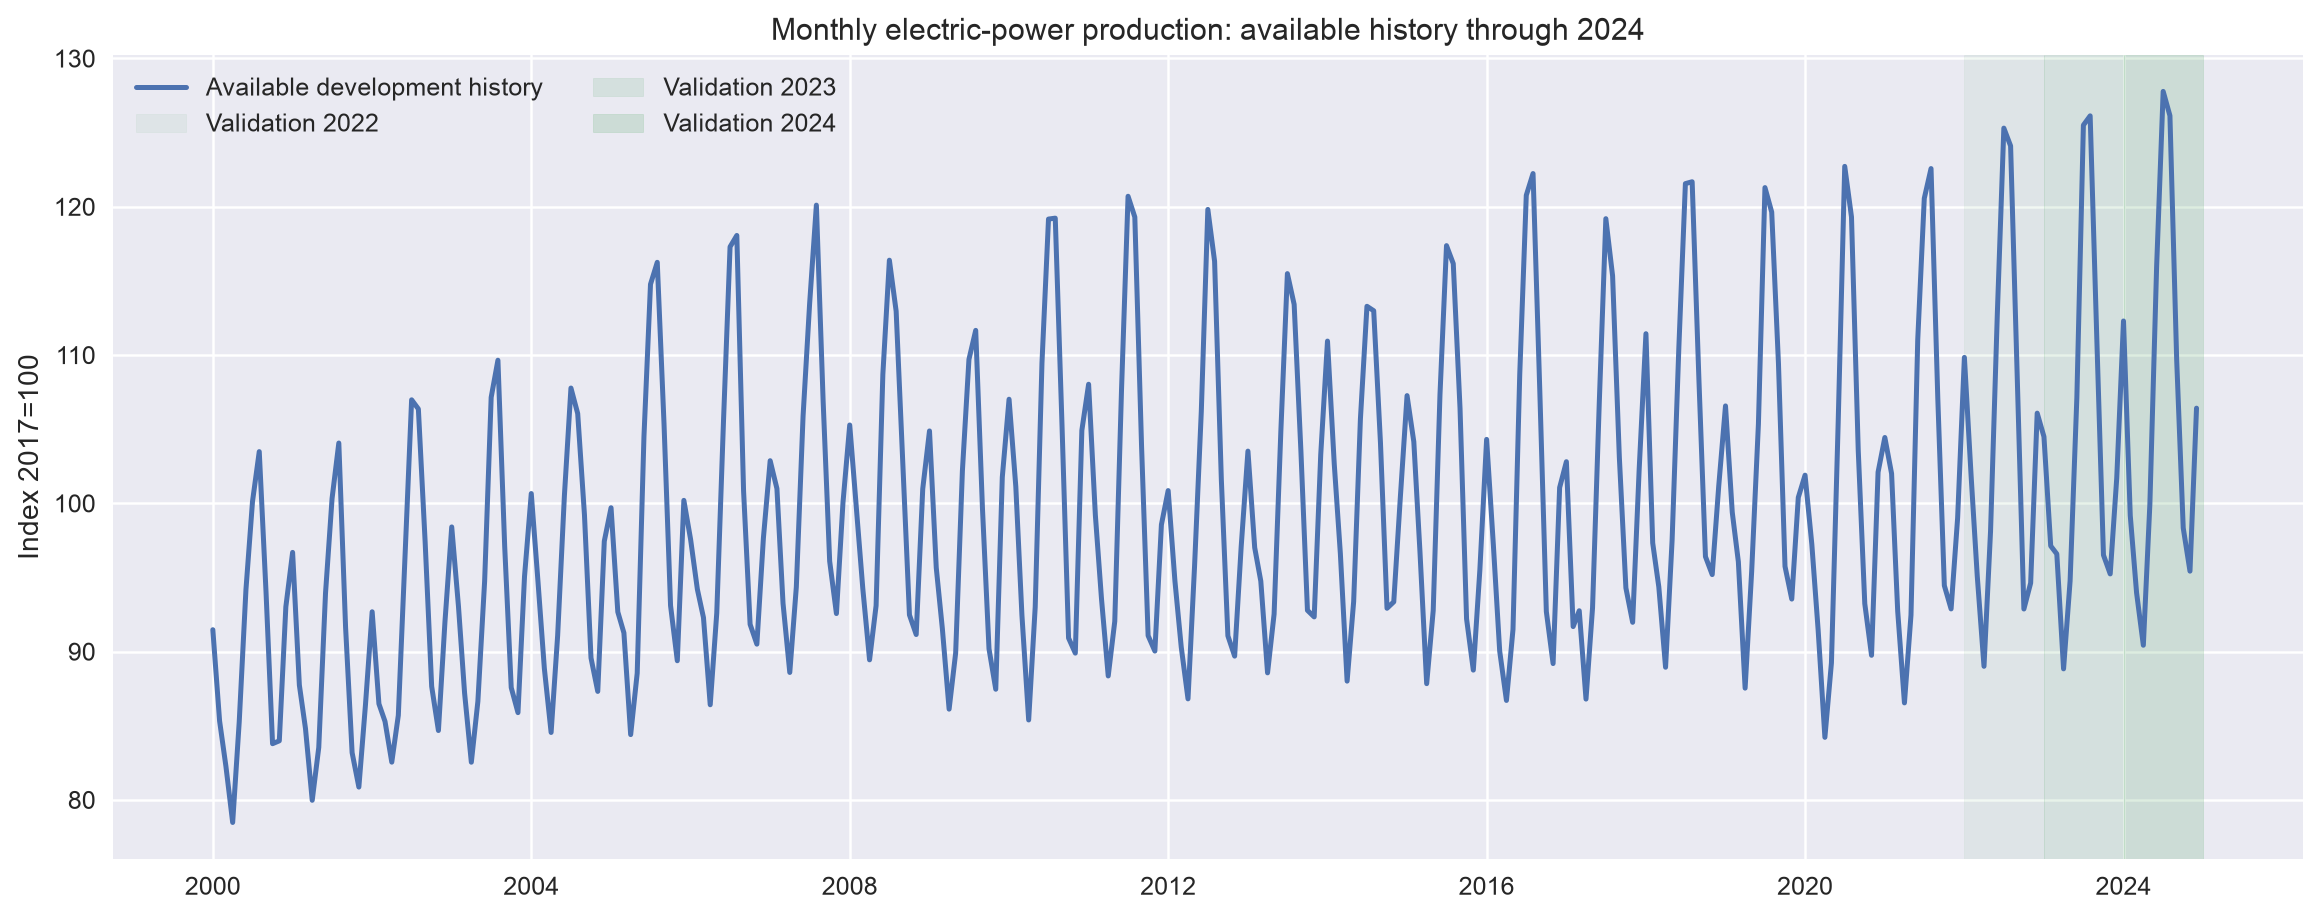

In [7]:
fig, ax = plt.subplots(figsize=(CFG.img_dim1 * CFG.publication_scale,
                                CFG.img_dim2 * CFG.publication_scale * 0.8))
ax.plot(development.index, development.values, color=CFG.colors["history"], lw=2,
        label="Available development history")
for year, alpha in [(2022, 0.08), (2023, 0.14), (2024, 0.20)]:
    ax.axvspan(pd.Timestamp(year, 1, 1), pd.Timestamp(year + 1, 1, 1),
               color=CFG.colors["forecast"], alpha=alpha, label=f"Validation {year}")
ax.set(title="Monthly electric-power production: available history through 2024",
       ylabel="Index 2017=100", xlabel="")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
save_graph(fig, workflow.HEADINGS[1], "development-plot", "Development history; final 2025 outcomes are withheld.")

This code generates a time-series plot of the `development` data, using color-coded background spans to indicate specific validation periods.

The visualization logic follows these steps:

* **Data Plotting:** The primary line plot displays the `development` series, utilizing the "history" color defined in `CFG`. The y-axis is labeled as "Index 2017=100," indicating the data has been normalized relative to the year 2017.
* **Temporal Highlighting:** To distinguish different validation windows, the code overlays vertical shaded regions (`axvspan`) for the years 2022, 2023, and 2024. The transparency (`alpha`) of these regions increases with each subsequent year (from 0.08 to 0.20), creating a visual gradient that differentiates more recent validation periods from earlier ones.
* **Formatting:** The plot is configured with a specific title regarding monthly electric-power production and includes a legend in the upper left, organized into two columns for readability. Figure dimensions are scaled based on the global `CFG` settings.

The final figure is passed to `save_graph`, where it is persisted as "development-plot" under the second heading of the workflow (`workflow.HEADINGS[1]`), with a caption noting that the 2025 outcomes are withheld from this view.

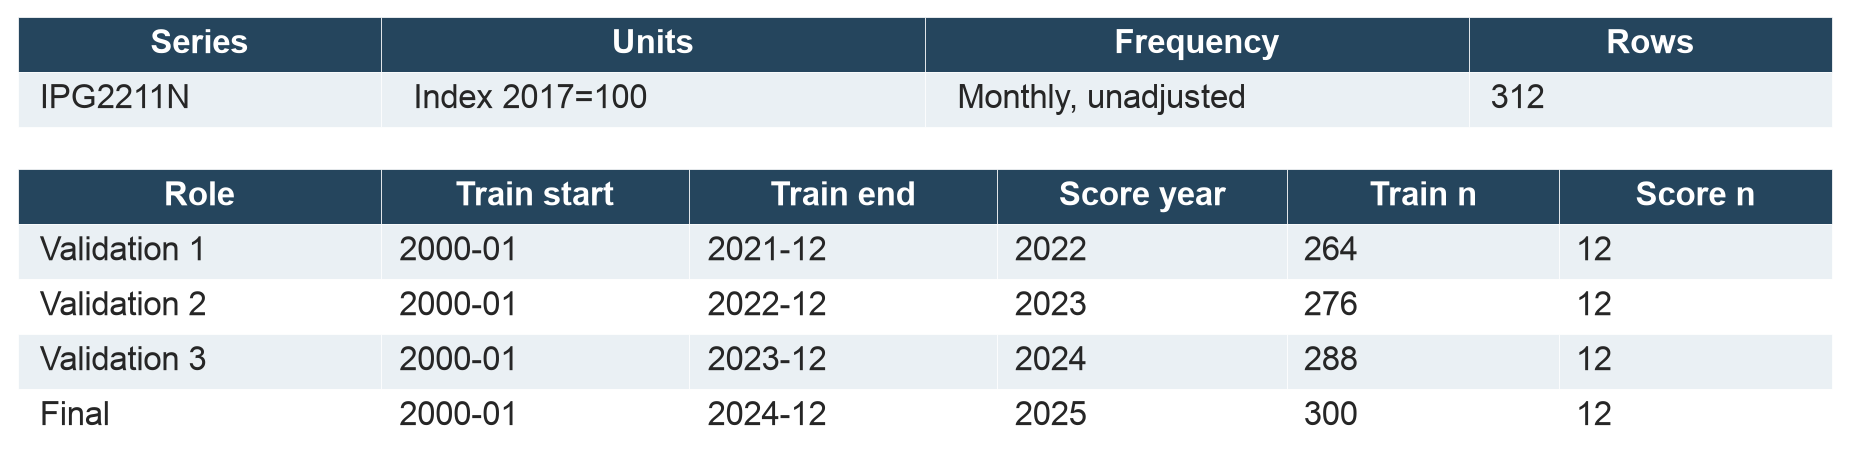

In [8]:
source_block = (["Series", "Units", "Frequency", "Rows"],
                [["IPG2211N", "Index 2017=100", "Monthly, unadjusted", 312]], [.2, .3, .3, .2])
protocol_rows = [["Validation 1", "2000-01", "2021-12", "2022", 264, 12],
                 ["Validation 2", "2000-01", "2022-12", "2023", 276, 12],
                 ["Validation 3", "2000-01", "2023-12", "2024", 288, 12],
                 ["Final", "2000-01", "2024-12", "2025", 300, 12]]
show_table([source_block, (["Role", "Train start", "Train end", "Score year", "Train n", "Score n"],
                           protocol_rows, [.2, .17, .17, .16, .15, .15])],
           workflow.HEADINGS[1], "protocol-table", "Source metadata and expanding chronological windows.")

This code prepares and renders two summary tables that document the dataset's properties and the experimental validation protocol used in the study.

The information is organized into two distinct structures:

* **Source Metadata Block:** This table provides high-level details about the raw time series, specifically its name (`IPG2211N`), units of measurement, frequency (monthly), and total row count. It includes a list of relative column widths to control the visual layout.
* **Protocol Table Data:** This table describes four chronological testing scenarios: three expanding validation windows and one final evaluation window. For each scenario, it specifies the role, the training period's start and end dates, the year being evaluated, and the number of observations used for both training (`Train n`) and scoring (`Score n`).

The `show_table` function is called with a list containing both of these table definitions. The resulting output is associated with the second heading in the workflow (`workflow.HEADINGS[1]`), assigned the unique identifier `"protocol-table"`, and accompanied by a caption describing them as "Source metadata and expanding chronological windows."

In [9]:
profile = numerical.profile(development)
early_facts = numerical.profile_evidence(profile)
verified_brief_stage = workflow.replay_stage(capture["stages"]["C.analyst"], "brief", early_facts)
print("Development lag-12 correlation:", f"{profile['lag12_correlation']:.2f}")
print("Analyst input verified:", verified_brief_stage["input_hash"][:12])
print("No model call; no 2025 values in this prompt.")

Development lag-12 correlation: 0.95
Analyst input verified: 5a873ff34fe6
No model call; no 2025 values in this prompt.


This code reconstructs a specific step in the previously recorded workflow—the "Analyst" stage (Stage C)—by generating an evidence-based brief derived from the statistical properties of the development data.

The process follows these steps:

* **Statistical Profiling:** The `numerical.profile` function analyzes the `development` time series to extract key characteristics. These statistics are then converted into a structured format through `numerical.profile_evidence`, which prepares them as "facts" suitable for inclusion in an analyst's brief.
* **Workflow Replay:** Using the `workflow.replay_stage` function, the code re-executes the `"C.analyst"` stage from the recorded session. It passes the newly generated `early_facts` into this stage to recreate the "brief" that was used during the original run.
* **Integrity Verification:** The code prints diagnostic information to ensure the replay is consistent with the original capture:
    * It displays the **lag-12 correlation** calculated from the profile.
    * It prints a truncated version of the `input_hash` from the replayed stage, allowing for manual verification that the input data matches the recorded session's state.
    * A status message confirms that this specific step does not involve external model calls or include any data from 2025.

# The numerical baseline

In [10]:
baseline_example = numerical.fit_method(development, "seasonal_naive")
assert baseline_example["forecast"] == development.iloc[-12:].tolist()
print("Seasonal naive copies 2024 into the corresponding months of 2025.")
print("Forecast dates:", baseline_example["dates"][0], "to", baseline_example["dates"][-1])
print("Declared catalog:")
for model, definition in numerical.CATALOG.items():
    print(model, "—", definition)

Seasonal naive copies 2024 into the corresponding months of 2025.
Forecast dates: 2025-01-01 to 2025-12-01
Declared catalog:
seasonal_naive — Repeat the last twelve observed months.
hw_add — Damped additive trend and additive seasonality, period twelve.
hw_mul — Damped additive trend and multiplicative seasonality, period twelve.


This code demonstrates and validates a "seasonal naive" baseline forecasting method, then prints the full list of available models from the system's catalog.

The execution follows these steps:

* **Baseline Modeling and Validation:** The `numerical.fit_method` function applies a `"seasonal_naive"` model to the `development` data. An assertion is used to verify the mathematical correctness of this specific method; it checks that the generated forecast is identical to the last 12 observations in the development series. This confirms the "seasonal naive" logic, where the next year's values are predicted by simply repeating the observations from the same months of the previous year.
* **Information Output:** Once validated, the code prints a descriptive message regarding the model's behavior and displays the specific date range covered by the resulting forecast.
* **Catalog Inspection:** Finally, the code iterates through `numerical.CATALOG` to print every available forecasting model and its associated definition, providing a summary of all methods supported by the `numerical` module.

In [11]:
print(json.dumps({"fit": numerical.PROTOCOL["fit"], "optimizer": numerical.PROTOCOL["optimizer"]}, indent=2))
frozen = numerical.prepare_forecast(development)
assert frozen["profile"]["prefix_hash"] == profile["prefix_hash"]
print("Selected:", frozen["selected_model"], "| Delivered:", frozen["delivered_model"])
print("Frozen forecast hash:", frozen["frozen_hash"])

{
  "fit": {
    "trend": "add",
    "damped_trend": true,
    "seasonal_periods": 12,
    "initialization_method": "estimated",
    "use_boxcox": false
  },
  "optimizer": {
    "optimized": true,
    "method": "L-BFGS-B",
    "use_brute": true,
    "remove_bias": false,
    "minimize_kwargs": {
      "options": {
        "maxiter": 2000
      }
    }
  }
}
Selected: hw_add | Delivered: hw_add
Frozen forecast hash: f7ef78e1246aec112f89185cc71fde3861e9a6261dc9393cbae1800e21b210db


This code executes the forecasting phase by applying predefined protocols to the development data and verifying the integrity of the results through cryptographic hashes.

The execution follows these steps:

* **Protocol Inspection:** The code first prints the current configuration settings for model fitting and optimization, retrieved from `numerical.PROTOCOL`, formatted as a structured JSON object.
* **Forecast Generation:** The `numerical.prepare_forecast` function is called using the `development` data to produce a "frozen" forecast object. 
* **Integrity Verification:** A critical assertion ensures that the `prefix_hash` within the newly generated forecast matches the hash of the statistical profile (`profile`) created in a previous step. This validates that the forecasting process is operating on the exact same data characteristics, maintaining strict reproducibility.
* **Outcome Reporting:** Finally, the code prints diagnostic metadata regarding the successful forecast:
    * The distinction between the `"selected"` model (the one identified as optimal) and the `"delivered"` model (the one actually produced).
    * The `frozen_hash`, which serves as a unique identifier for this specific forecast to ensure it can be audited or replayed without ambiguity.

In [12]:
archived = json.loads((CFG.example_folder / "frozen_forecast.json").read_text())
assert numerical.semantic(frozen) == numerical.semantic(archived)
evaluation = numerical.score_frozen(frozen, final_outcomes)
facts = numerical.result_evidence(frozen, evaluation)
print("Frozen predictions match the archive; final outcomes have now been scored.")
print("Delivered RMSE:", f"{evaluation['delivered']['rmse']:.2f}")
print("Baseline RMSE:", f"{evaluation['baseline']['rmse']:.2f}")

Frozen predictions match the archive; final outcomes have now been scored.
Delivered RMSE: 3.00
Baseline RMSE: 3.44


This code validates the reproducibility of the forecasting process and performs a final evaluation by comparing the "frozen" forecast against actual historical observations.

The execution follows these logical steps:

*   **Reproducibility Verification:** The code loads an archived forecast from `frozen_forecast.json`. It then uses `numerical.semantic()` to compare the current `frozen` object with this archived version. This assertion ensures that the replay has successfully reproduced the exact same predictive results as the original run, verifying that the forecasting pipeline is deterministic and stable.
*   **Performance Evaluation:** Once reproducibility is confirmed, the `numerical.score_frozen` function compares the forecast against the actual values stored in `final_outcomes`. This calculates error metrics to quantify the model's accuracy.
*   **Evidence Generation:** The resulting evaluation data is passed to `numerical.result_evidence`, which transforms the numerical performance metrics into structured "facts." These facts are intended for use in subsequent automated reporting or diagnostic explanations.

Finally, the code prints a confirmation of the successful match and displays the Root Mean Square Error (RMSE) for both the delivered model and the baseline, providing a direct comparison of their predictive accuracy.

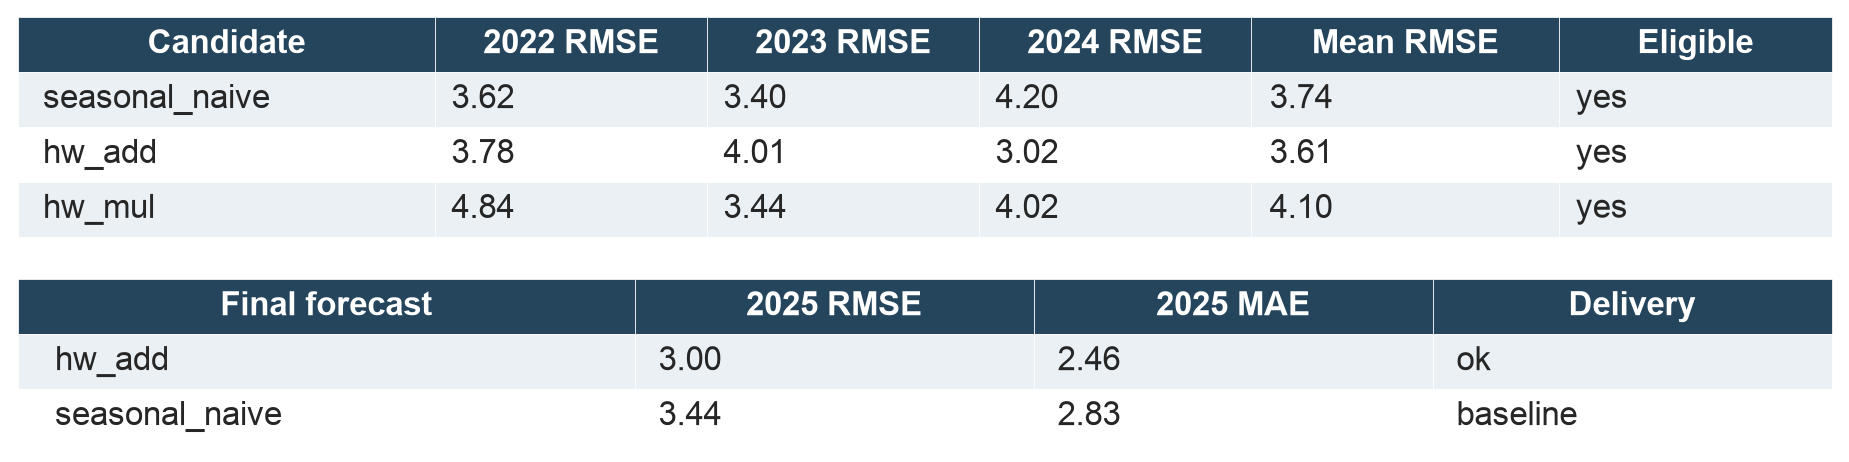

In [13]:
validation_rows = []
for model, result in frozen["backtest"].items():
    validation_rows.append([model, *[fold.get("metrics", {}).get("rmse") for fold in result["folds"]],
                            result["mean_rmse"], "yes" if result["eligible"] else "no"])
final_rows = [[frozen["delivered_model"], evaluation["delivered"]["rmse"], evaluation["delivered"]["mae"], frozen["delivery_status"]],
              ["seasonal_naive", evaluation["baseline"]["rmse"], evaluation["baseline"]["mae"], "baseline"]]
show_table([(["Candidate", "2022 RMSE", "2023 RMSE", "2024 RMSE", "Mean RMSE", "Eligible"],
             validation_rows, [.23, .15, .15, .15, .17, .15]),
            (["Final forecast", "2025 RMSE", "2025 MAE", "Delivery"], final_rows, [.34, .22, .22, .22])],
           workflow.HEADINGS[2], "scores-table", "Validation scores and the frozen final comparison, in index points.")

This code aggregates and visualizes the performance metrics for candidate models during the backtesting phase and provides a final comparison between the delivered forecast and a baseline for the target year (2025).

The data is organized into two distinct tables:

* **Validation Scores Table:** This table summarizes how each model performed across the historical validation windows. The code iterates through the `frozen["backtest"]` dictionary to construct rows containing:
    * The model's name.
    * The Root Mean Square Error (RMSE) for each specific validation year (2022, 2023, and 2024).
    * The mean RMSE across all folds.
    * An eligibility flag indicating whether the model met necessary criteria for selection.

* **Final Forecast Comparison Table:** This table presents a side-by-side evaluation of the final results for the year 2025. It compares:
    * The **delivered model**, displaying its RMSE, Mean Absolute Error (MAE), and current delivery status.
    * The **seasonal naive baseline**, displaying its corresponding RMSE and MAE.

The `show_table` function renders these two tables under the third heading of the workflow (`workflow.HEADINGS[2]`), assigned the ID `"scores-table"`. A caption specifies that the values are reported in index points.

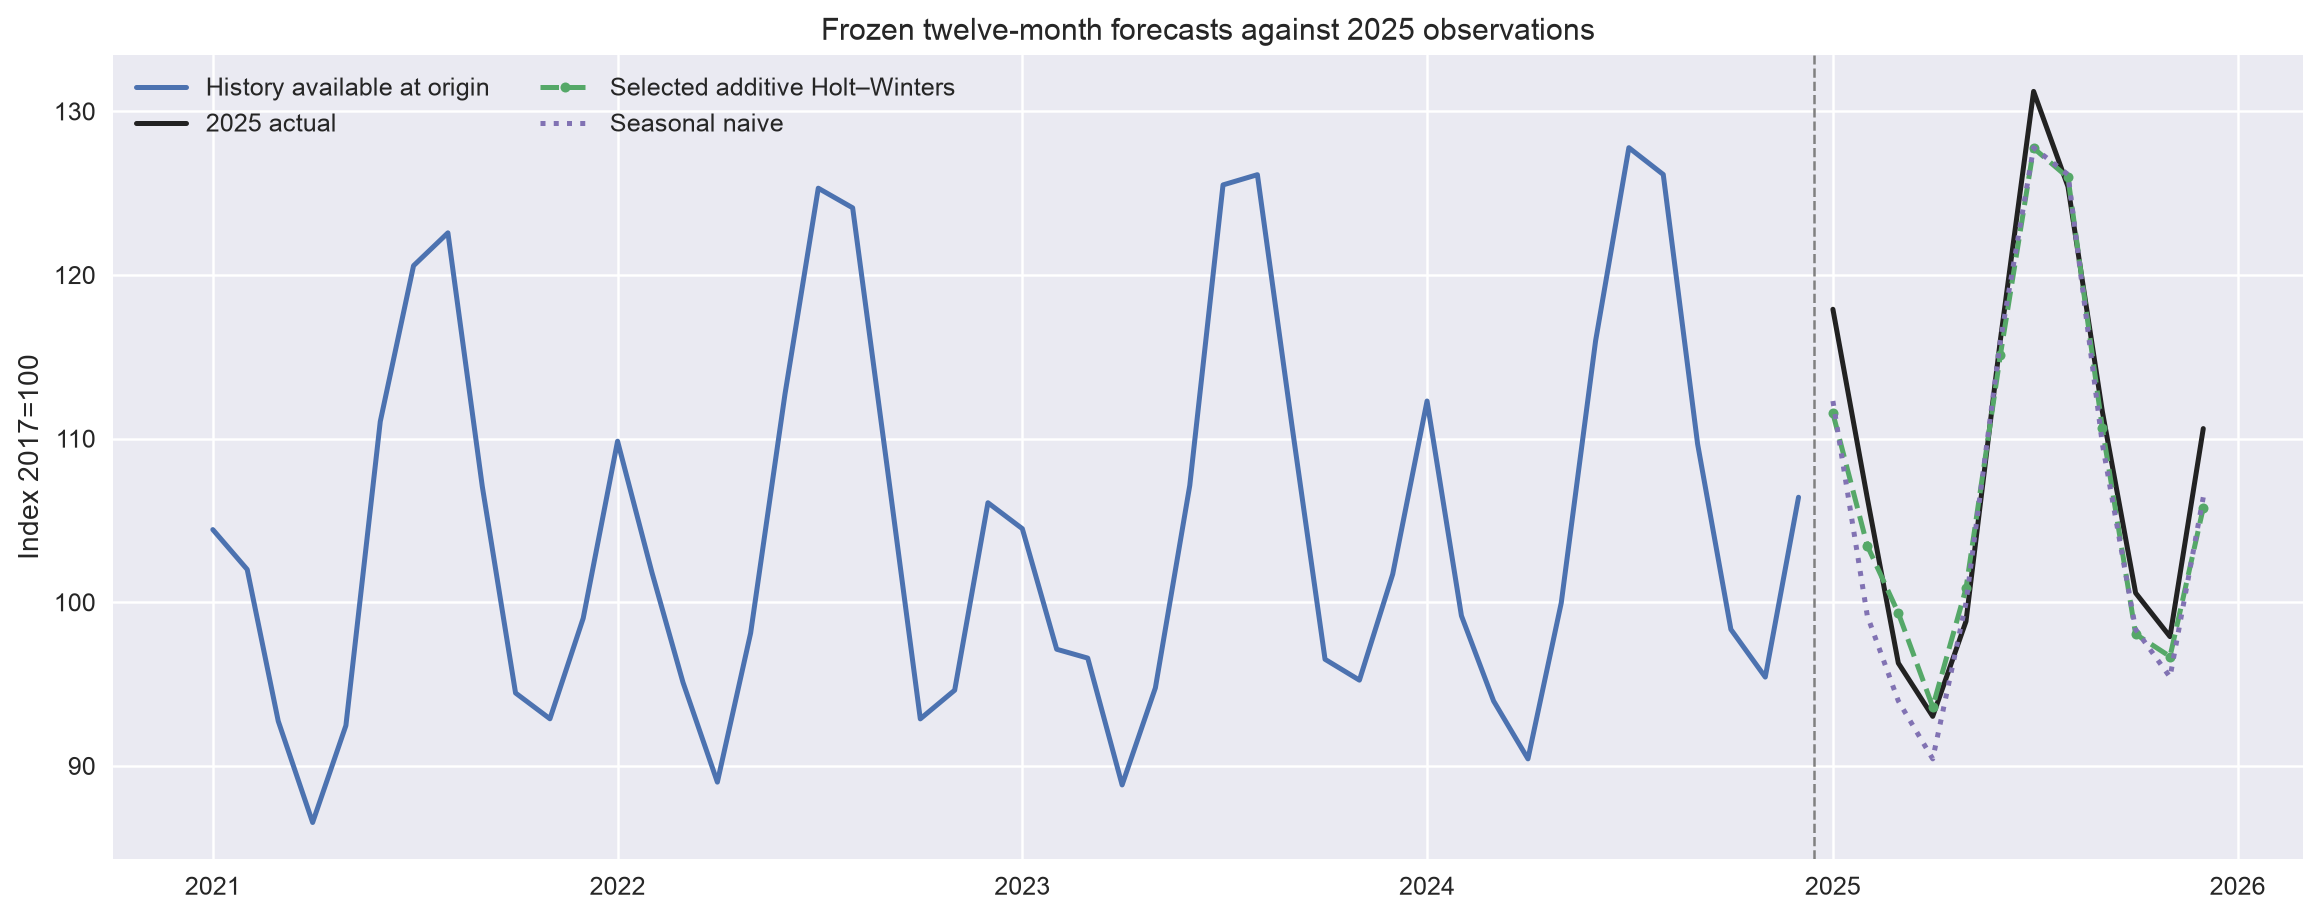

In [14]:
fig, ax = plt.subplots(figsize=(CFG.img_dim1 * CFG.publication_scale,
                                CFG.img_dim2 * CFG.publication_scale * 0.8))
recent = development.loc["2021-01-01":]
ax.plot(recent.index, recent.values, lw=2, color=CFG.colors["history"], label="History available at origin")
ax.plot(final_outcomes.index, final_outcomes.values, lw=2, color=CFG.colors["actual"], label="2025 actual")
ax.plot(final_outcomes.index, frozen["forecast"], lw=2, ls="--", marker="o", markersize=4,
        color=CFG.colors["forecast"], label="Selected additive Holt–Winters")
ax.plot(final_outcomes.index, frozen["baseline_forecast"], lw=2, ls=":",
        color=CFG.colors["baseline"], label="Seasonal naive")
ax.axvline(pd.Timestamp("2024-12-15"), color="gray", ls="--", lw=1)
ax.set(title="Frozen twelve-month forecasts against 2025 observations", ylabel="Index 2017=100", xlabel="")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
save_graph(fig, workflow.HEADINGS[2], "forecast-plot", "Final observed values and frozen selected/baseline forecasts.")

This code generates a comparison plot that overlays historical data, actual 2025 observations, and two competing forecasts to visually evaluate model performance.

The visualization is constructed using four distinct data layers:

* **Recent History:** To provide relevant context without cluttering the view, the plot shows only the most recent portion of the development series (from January 1, 2021, onwards) in the standard history color.
* **Actual Outcomes:** The true values for the year 2025 are plotted as a solid line using the "actual" color.
* **Selected Model Forecast:** The primary forecast—identified in the legend as an "Additive Holt–Winters" model—is displayed as a dashed line with circular markers.
* **Baseline Forecast:** The seasonal naive baseline is represented by a dotted line, allowing for a direct visual comparison against the selected model.

The plot includes a vertical gray dashed line at December 15, 2024, which serves to mark the transition between the historical data and the period being forecasted. The y-axis is labeled as "Index 2017=100," consistent with previous visualizations.

The final figure is scaled according to the global configuration, formatted with a two-column legend in the upper left, and saved via `save_graph` under the third workflow heading (`workflow.HEADINGS[2]`) with the identifier `"forecast-plot"`.

# From results to handoffs

In [15]:
print("Evidence IDs:")
print("\n".join(sorted(facts)))
print("\nExample authoritative fact:")
print(json.dumps(facts["forecast.delivery"], indent=2))
print("\nReport fields:", list(workflow.schema("report", facts)["properties"]))

Evidence IDs:
catalog.hw_add
catalog.hw_mul
catalog.seasonal_naive
data.meaning
data.profile
evaluation.final
forecast.delivery
limitations.scope
limitations.uncertainty
limitations.vintage
limitations.workflow
protocol.selection
protocol.validation
validation.results

Example authoritative fact:
{
  "selected_model": "hw_add",
  "delivered_model": "hw_add",
  "delivery_status": "ok"
}

Report fields: ['selection', 'evaluation', 'limitation']


This code performs a diagnostic inspection of the structured "evidence facts" generated during the scoring process to ensure they are correctly formatted and compatible with the reporting schema.

The execution prints three distinct sets of information for verification:

* **Evidence Inventory:** A sorted list of all available keys within the `facts` dictionary, providing an overview of every unique identifier captured during the evaluation.
* **Fact Structure Example:** The content associated with the `"forecast.delivery"` key is printed as a formatted JSON object. This serves as a concrete example of how individual evidence items are structured (typically containing textual claims and metadata).
* **Schema Validation:** The code queries `workflow.schema` to determine which properties from the current `facts` context are officially recognized as valid fields for a "report." By printing these property names, it confirms that the generated facts align with the expected input requirements for the final automated reporting stage.

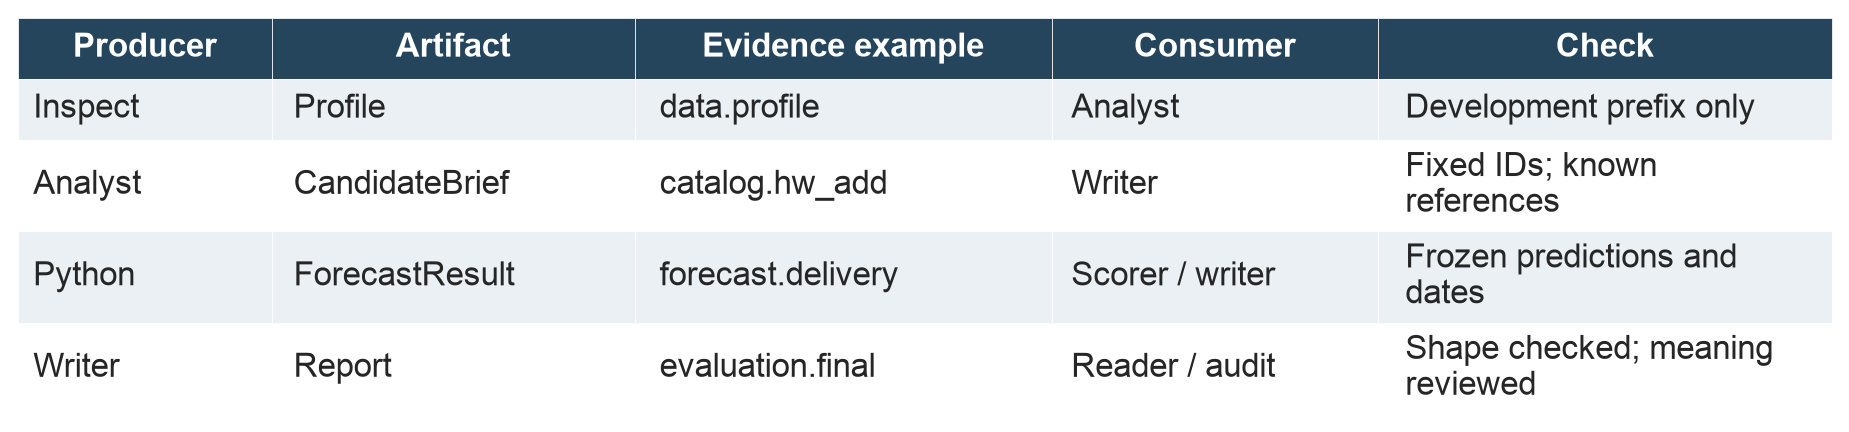

In [16]:
handoffs = [["Inspect", "Profile", "data.profile", "Analyst", "Development prefix only"],
            ["Analyst", "CandidateBrief", "catalog.hw_add", "Writer", "Fixed IDs; known references"],
            ["Python", "ForecastResult", "forecast.delivery", "Scorer / writer", "Frozen predictions and dates"],
            ["Writer", "Report", "evaluation.final", "Reader / audit", "Shape checked; meaning reviewed"]]
show_table([(["Producer", "Artifact", "Evidence example", "Consumer", "Check"], handoffs, [.14, .2, .23, .18, .25])],
           workflow.HEADINGS[3], "handoff-table", "Four structured handoffs and the checks they support.")

This code generates a summary table documenting the structured information flow—or "handoffs"—between different roles and stages in an automated multi-step workflow.

The table describes four critical transitions of control and data:

* **Inspect to Analyst:** Passes a statistical "Profile" (identified by `data.profile`) for analysis, with a verification check that it contains only development prefix data.
* **Analyst to Writer:** Passes a "CandidateBrief" (using the reference `catalog.hw_add`) to the writer, verified by ensuring fixed IDs and known references are present.
* **Python to Scorer/Writer:** The system passes the "ForecastResult" (identified by `forecast.delivery`), which is checked for the integrity of frozen predictions and dates.
* **Writer to Reader/Audit:** The final "Report" (identified by `evaluation.final`) is passed to the consumer, with a verification check on both its data shape and semantic meaning.

Each row in the `handoffs` list defines five dimensions of this process: the **Producer** of the information, the name of the **Artifact** being transferred, an **Evidence example** (a specific key used for tracking), the intended **Consumer**, and the specific **Check** required to validate the transfer.

The resulting table is rendered with customized column widths and is saved as `"handoff-table"` under the fourth heading in the workflow (`workflow.HEADINGS[3]`).

# Comparison

In [17]:
with patch("urllib.request.urlopen", side_effect=AssertionError("Network disabled during replay")), \
     patch("agentic_ts.module01_workflow.urlopen", side_effect=AssertionError("Model server disabled during replay")):
    replay = workflow.verify_replay(capture, frozen, evaluation, manifest)
assert replay["new_model_calls"] == 0
numerical.write_json(CFG.example_folder / "replay_verification.json", replay)
print("Replay:", replay["status"], "| New model calls:", replay["new_model_calls"])
print("Genuine completed handoff:", capture["genuine_handoff"])

Replay: matched | New model calls: 0
Genuine completed handoff: True


This code performs a formal verification of the replay process to ensure that the execution is entirely self-contained and does not rely on any external network or model server requests.

The verification logic utilizes two layers of defensive programming:

*   **Network Isolation:** The `patch` context managers intercept both standard `urllib.request.urlopen` calls and the workflow-specific `urlopen` utility. Both are configured to raise an `AssertionError` if invoked, guaranteeing that the replay environment remains strictly offline.
*   **Replay Validation:** The `workflow.verify_replay` function compares the current session state—comprising the original capture (`capture`), the generated forecast (`frozen`), the evaluation results (`evaluation`), and the data metadata (`manifest`)—against the recorded session to detect any discrepancies.

The code enforces a strict reproducibility requirement by asserting that `new_model_calls` is exactly zero, proving that no external model servers were consulted during the process. Finally, the verification report is persisted to `replay_verification.json`, and the status of the replay along with the original session's handoff integrity is printed to the console.

In [18]:
print_brief(verified_brief_stage["output"])

**seasonal_naive:** Seasonal naive repeats the last twelve observed months, offering a simple baseline for strong seasonal patterns.

Evidence IDs: `data.profile`

**hw_add:** Holt-Winters additive model with damped trend and additive seasonality may capture additive seasonal shifts and trend decay.

Evidence IDs: `catalog.hw_add`

**hw_mul:** Holt-Winters multiplicative seasonality may better handle proportional seasonal variation as levels change over time.

Evidence IDs: `catalog.hw_mul`

**Limitation:** Performance is based on one series, point forecasts only, no real-time vintage, and catalog selection is fixed outside modeler control.

In [19]:
for arm, description in [("A", "Python template"), ("B", "Single-call report"), ("C", "Chained report")]:
    print_report(f"{arm}: {description}", replay["arms"][arm]["report"])

**A: Python template**

**Selection:** hw_add minimized mean RMSE across the 2022, 2023 and 2024 validation years. Delivered hw_add; delivery status: ok.

Evidence IDs: `protocol.selection, validation.results, forecast.delivery`

**Evaluation:** January–December 2025: delivered RMSE 3.00 and MAE 2.46 index points; seasonal-naive RMSE 3.44 and MAE 2.83. Delivered RMSE is lower than the baseline.

Evidence IDs: `evaluation.final, data.profile`

**Limitation:** This revised snapshot does not reproduce the data vintage available at each historical origin. One series and one final year do not establish general forecasting or reporting performance.

Evidence IDs: `limitations.vintage, limitations.scope`

**B: Single-call report**

**Selection:** hw_add (damped additive trend, additive seasonality, period 12) was selected as validation-minimum RMSE model; no fallback was needed.

Evidence IDs: `catalog.hw_add, validation.results, forecast.delivery, protocol.selection`

**Evaluation:** For Jan-Dec 2025, the delivered hw_add model achieved RMSE 3.00 and MAE 2.46, versus baseline RMSE 3.44 and MAE 2.83; RMSE is 0.43 lower.

Evidence IDs: `evaluation.final, forecast.delivery`

**Limitation:** Performance is based on one series, three validation years, and one final year; this does not establish generalizability across series or contexts.

Evidence IDs: `limitations.scope`

**C: Chained report**

**Selection:** hw_add selected by minimum mean three-fold RMSE (3.61 vs. hw_mul 4.10, seasonal_naive 3.74); no fallback needed.

Evidence IDs: `protocol.selection, validation.results, forecast.delivery`

**Evaluation:** Jan-Dec 2025 delivered RMSE 3.00 and MAE 2.46, versus baseline RMSE 3.44 and MAE 2.83; RMSE is 0.43 lower (12.6% improvement).

Evidence IDs: `evaluation.final, validation.results`

**Limitation:** One series, three validation years, and one final year do not establish general performance across diverse power-generation contexts.

Evidence IDs: `limitations.scope`

This code iterates through three distinct execution paths (labeled Arms A, B, and C) to display their respective diagnostic reports.

The loop processes each arm using the following logic:
*   **Label Construction:** It generates a descriptive label for each report based on its identifier and intended purpose: "A: Python template", "B: Single-call report", and "C: Chained report".
*   **Report Retrieval and Rendering:** It extracts the structured report data from the `replay` object using the path `["arms"][arm]["report"]`. This data is then passed to the `print_report` function, which renders the claims and evidence IDs associated with that specific execution path as formatted Markdown.

This step serves as the final qualitative comparison of the different operational modes investigated during the workflow replay.

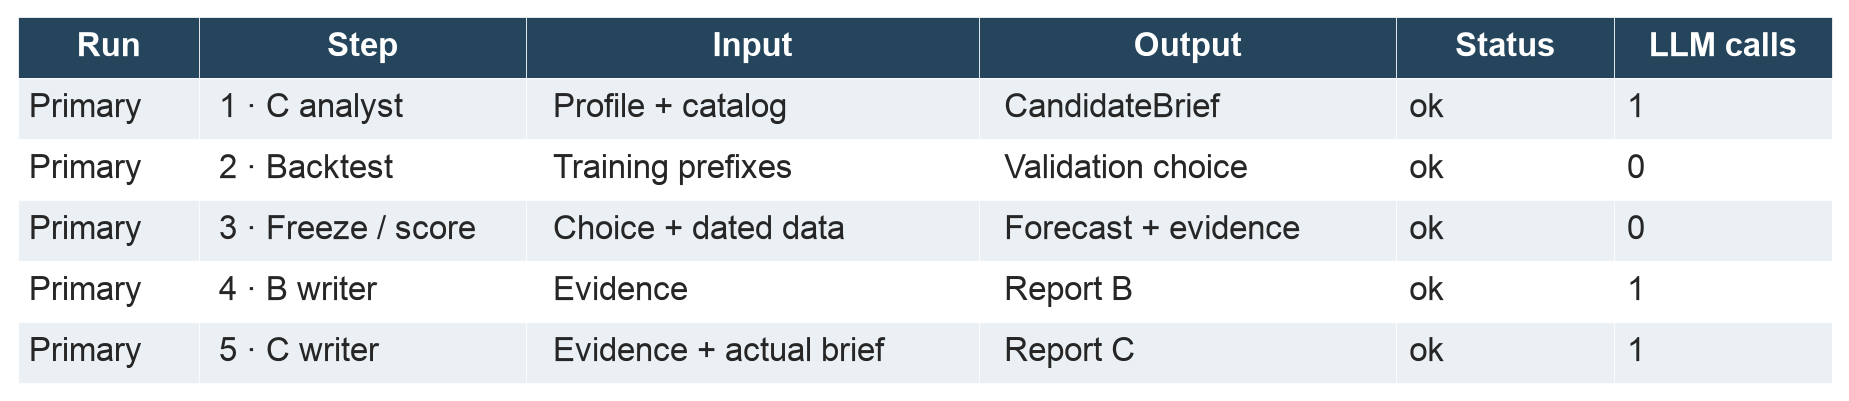

In [20]:
trace_rows = [["Primary", "1 · C analyst", "Profile + catalog", "CandidateBrief", capture["stages"]["C.analyst"]["status"], 1],
              ["Primary", "2 · Backtest", "Training prefixes", "Validation choice", "ok", 0],
              ["Primary", "3 · Freeze / score", "Choice + dated data", "Forecast + evidence", frozen["delivery_status"], 0],
              ["Primary", "4 · B writer", "Evidence", "Report B", capture["stages"]["B.writer"]["status"], 1],
              ["Primary", "5 · C writer", "Evidence + actual brief", "Report C", capture["stages"]["C.writer"]["status"], 1]]
show_table([(["Run", "Step", "Input", "Output", "Status", "LLM calls"], trace_rows, [.1, .18, .25, .23, .12, .12])],
           workflow.HEADINGS[4], "trace-table", "Chronology of the genuine primary capture; the template also ran before B.")

This code generates a traceability table that documents the chronological execution history of the original ("genuine") primary workflow capture.

The table provides an audit trail for five specific operational steps:

* **Step 1 (C Analyst):** Records the use of the Profile and catalog as inputs to produce a `CandidateBrief`, pulling the status from the captured session metadata.
* **Step 2 (Backtest):** Documents the training prefixes used to make validation choices, with a hardcoded "ok" status.
* **Step 3 (Freeze / Score):** Tracks how the model choice and dated data are converted into a forecast and evidence, using the current `delivery_status` of the frozen forecast.
* **Step 4 (B Writer):** Records the transition from evidence to "Report B," retrieving the status from the captured session.
* **Step 5 (C Writer):** Records the transition from evidence and the actual brief to "Report C," also retrieving its status from the captured session.

For each step, the table logs the run type ("Primary"), the input artifacts, the resulting output, the execution status, and the number of LLM calls performed (either 0 or 1). The final table is rendered under the fifth heading in the workflow (`workflow.HEADINGS[4]`) with the identifier `"trace-table"` and a caption noting that this represents the genuine primary capture and that a template run also occurred prior to the "B writer" stage.

# Verification and checks

In [21]:
audit = json.loads((CFG.example_folder / "claim_audit.json").read_text())
assert audit["capture_hash"] == capture["bundle_hash"]
assert audit["audit_hash"] == numerical.digest({k: v for k, v in audit.items() if k != "audit_hash"})
print(audit["review_method"])
for arm in "ABC":
    print(arm, audit["summary"][arm], audit["completeness_notes"][arm])
print("\nBrief issues:")
for item in audit["brief"]:
    if item["status"] in {"unsupported", "ambiguous"}:
        print(item["id"], item["status"], item["note"])

Codex-assisted editorial inspection against source facts plus independent arithmetic checks; not a blinded human study or model self-grade.
A {'total': 17, 'supported': 16, 'contradicted': 0, 'unsupported': 1, 'ambiguous': 0} Required structure, selection rule, final date range and units are explicit. One true date claim lacks its direct supporting citation; the original template is preserved.
B {'total': 18, 'supported': 18, 'contradicted': 0, 'unsupported': 0, 'ambiguous': 0} Valid structure and correct values; does not explicitly state index-point units or three-fold averaging in the report text.
C {'total': 19, 'supported': 19, 'contradicted': 0, 'unsupported': 0, 'ambiguous': 0} Valid structure and correct values; does not state index-point units. Adds an unrequested, one-decimal derived percentage.

Brief issues:
brief.1 unsupported The statement is true, but its sole citation data.profile contains no algorithm definition. catalog.seasonal_naive would support it.
brief.9 ambiguou

This code verifies the integrity of a claim audit file and displays its qualitative findings, including summaries for different execution paths and specific issues identified in the analytical briefs.

The process begins with rigorous data integrity checks to ensure the audit is both authentic and untampered:

* **Provenance Verification:** The code compares the `capture_hash` within the loaded JSON to the `bundle_hash` of the current session. This ensures that the audit being read corresponds exactly to the specific execution run currently being replayed.
* **Integrity Verification:** It validates the `audit_hash` by recalculating a digest of all other fields in the audit object. This confirms that no part of the audit data has been modified since it was originally recorded.

Once integrity is confirmed, the code outputs the results of the audit:

* **Methodology and Summary:** It prints the method used for the review and then iterates through execution arms A, B, and C. For each arm, it displays a high-level summary and specific notes regarding the completeness of the findings.
* **Brief Issue Identification:** Finally, the code performs a targeted scan of the `"brief"` section. It filters for items specifically flagged with an `"unsupported"` or `"ambiguous"` status, printing their unique identifiers, status, and accompanying explanatory notes. This highlights potential weaknesses or uncertainties in the automated reasoning process.

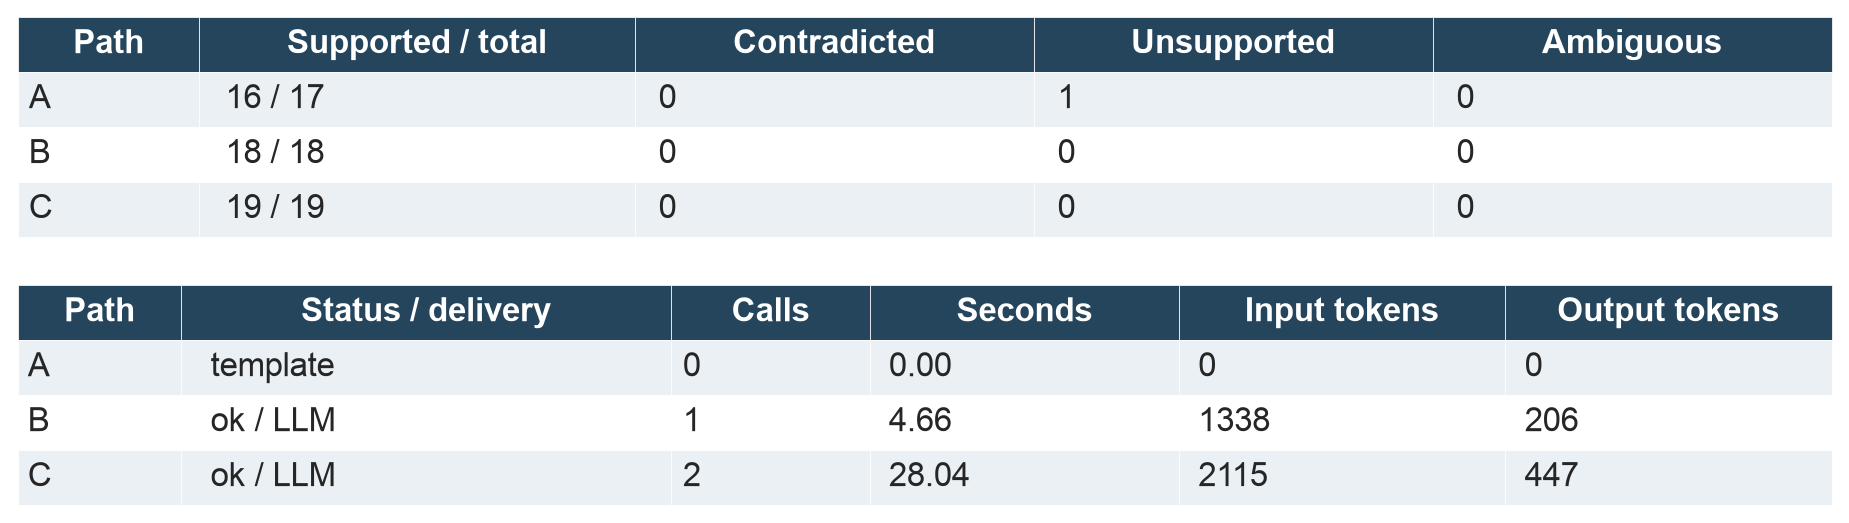

In [22]:
audit_rows = [[arm, f"{audit['summary'][arm]['supported']} / {audit['summary'][arm]['total']}",
               audit["summary"][arm]["contradicted"], audit["summary"][arm]["unsupported"],
               audit["summary"][arm]["ambiguous"]] for arm in "ABC"]
work_rows = [["A", "template", 0, capture["template_seconds"], 0, 0]]
for arm, stages in [("B", ["B.writer"]), ("C", ["C.analyst", "C.writer"])]:
    records = [capture["stages"][key] for key in stages]
    def total_usage(key):
        values = [r["usage"].get(key) for r in records]
        return sum(values) if all(v is not None for v in values) else None
    work_rows.append([arm, "ok / LLM", len(records), sum(r["request_seconds"] for r in records),
                      total_usage("prompt_eval_count"), total_usage("eval_count")])
show_table([(["Path", "Supported / total", "Contradicted", "Unsupported", "Ambiguous"],
             audit_rows, [.1, .24, .22, .22, .22]),
            (["Path", "Status / delivery", "Calls", "Seconds", "Input tokens", "Output tokens"],
             work_rows, [.09, .27, .11, .17, .18, .18])],
           workflow.HEADINGS[5], "audit-work-table", "Final-report factual audit and archived reporting work.")

This code prepares and renders two summary tables that provide a quantitative comparison of factual accuracy and operational effort across the three execution paths (Arms A, B, and C).

**The Factual Audit Table**
The first table aggregates data from the previously loaded `audit` object to evaluate the quality of the claims generated in each arm. For every path, it calculates:
*   A success ratio showing **supported claims versus the total number of claims**.
*   The absolute count of claims categorized as **contradicted**, **unsupported**, or **ambiguous**.

**The Operational Work Table**
The second table tracks the computational and linguistic "cost" associated with each path. The logic differs based on the complexity of the arm:
*   **Arm A (Template):** Records a simple baseline showing zero LLM calls and the time taken for the template execution.
*   **Arms B and C (LLM-driven):** These paths involve active model interactions. The code identifies the specific stages belonging to each arm (e.g., "B.writer" for Arm B; "C.analyst" and "C.writer" for Arm C) and aggregates their metrics. It calculates:
    *   The number of stages involved.
    *   The total execution time in seconds.
    *   Total **input tokens** (prompt evaluation counts).
    *   Total **output tokens** (completion counts).

The two tables are presented together using `show_table` under the sixth heading of the workflow (`workflow.HEADINGS[5]`), with the identifier `"audit-work-table"` and a caption describing them as the "Final-report factual audit and archived reporting work."

In [23]:
analyst_load = capture["stages"]["C.analyst"]["metadata"]["load_duration"] / 1_000_000_000
print(f"C analyst request: {capture['stages']['C.analyst']['request_seconds']:.2f} s")
print(f"Server-reported model load within that request: {analyst_load:.2f} s")
print(f"Common archived numerical work: {capture['numerical_seconds']:.2f} s")
print(f"Current replay verification: {replay['replay_seconds']:.2f} s (no inference)")
for item in audit["brief_use"]:
    print(item["item"], "—", item["writer_treatment"], "—", item["evidence"])

C analyst request: 23.67 s
Server-reported model load within that request: 19.22 s
Common archived numerical work: 0.29 s
Current replay verification: 0.00 s (no inference)
seasonal-naive rationale — ignored — The final writer supplies its measured score but does not reuse or repair the rationale or bad citation.
additive rationale — ignored — The writer reports the validation winner. It does not discuss the earlier component hypothesis.
multiplicative rationale — ignored — The writer gives hw_mul validation RMSE without discussing the proportional-seasonality hypothesis.
one-series qualification — retained — The final limitation repeats limited scope. B states the same qualification without receiving the brief, so this is not proof of its causal contribution.
point-only, vintage and fixed-catalog notes — ignored — These brief limitations are absent from C’s final report.


This code performs a performance latency analysis of the workflow stages and provides a qualitative audit of how specific elements from the analyst's brief were handled during the writing process.

The execution consists of two distinct parts:

**Latency Breakdown and Comparison**
The code extracts timing metadata to compare the original execution against the current replay session:
* **Analyst Stage Latency:** It calculates the time spent loading the model during the "C.analyst" stage by converting a nanosecond value from the captured metadata into seconds. It then prints both this load duration and the total request duration for that stage.
* **Numerical Computation Time:** It displays the total time spent on numerical calculations recorded in the original `capture`.
* **Replay Efficiency:** It prints the duration of the current replay process, explicitly noting that this time excludes any model inference, which allows for a comparison of the computational overhead between a live run and a verified replay.

**Brief Usage Audit**
Finally, the code iterates through the `"brief_use"` section of the `audit` object. For each item in the brief, it prints:
* The specific **item identifier**.
* The **writer's treatment** (how the information was interpreted or processed).
* The **evidence** used to support that specific part of the brief.

This provides transparency into how the automated "Writer" interacted with the facts provided by the "Analyst."


# Failed handoff- visible

In [24]:
before_failure = numerical.digest(facts)
failure = workflow.failure_fixture(facts)
assert failure["mode"] == "injected"
assert failure["stage"]["status"] == "failed"
assert failure["writer_calls"] == 0
assert numerical.digest(facts) == before_failure
numerical.write_json(CFG.example_folder / "failure_fixture.json", failure)
print(failure["stage"]["error"])

ValueError: Unknown or empty evidence ID


This code simulates a controlled system failure by generating an "injected" failure fixture based on the current set of evidence facts, ensuring that this simulation can be used for testing or debugging without altering the original data.

The process follows these steps:

* **State Baselining:** The code first creates a cryptographic digest of the `facts` object to establish a baseline of its current state.
* **Failure Simulation:** It calls `workflow.failure_fixture(facts)` to generate a specialized object designed to represent a broken workflow state. 
* **Integrity and Logic Validation:** A series of assertions are used to verify that the simulated failure is valid and follows specific constraints:
    * The failure mode must be explicitly labeled as `"injected"`.
    * The status of the affected stage must be marked as `"failed"`.
    * No calls to the "writer" should have been initiated in this failure state.
    * **Immutability Check:** It verifies that the original `facts` object remains completely unchanged by comparing its current digest to the pre-failure baseline.
* **Persistence and Reporting:** The resulting failure fixture is saved as a JSON file (`failure_fixture.json`) for future use in reproducing this error. Finally, the specific error message contained within the failed stage is printed to the console.

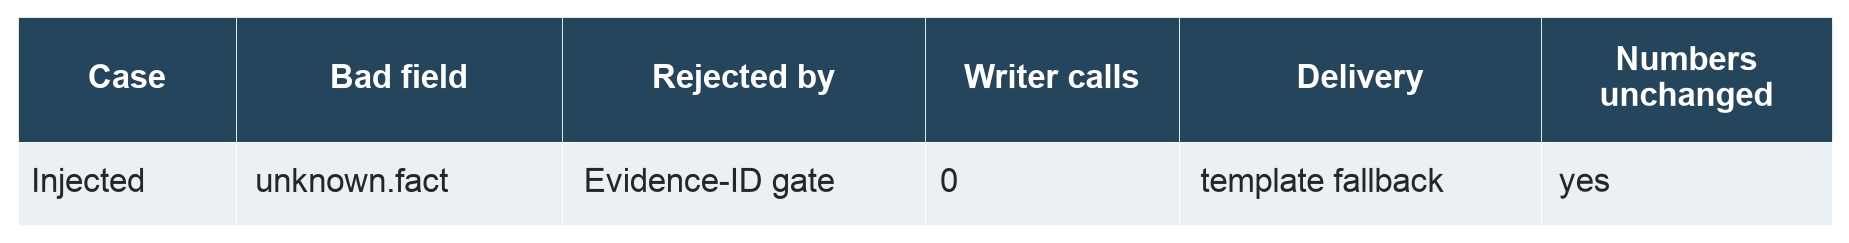

In [25]:
failure_rows = [["Injected", "unknown.fact", "Evidence-ID gate", failure["writer_calls"],
                 failure["delivery"]["report_type"], "yes" if failure["numerical_evidence_unchanged"] else "no"]]
show_table([(["Case", "Bad field", "Rejected by", "Writer calls", "Delivery", "Numbers unchanged"],
             failure_rows, [.12, .18, .2, .14, .2, .16])],
           workflow.HEADINGS[6], "failure-table", "One injected unknown-reference failure, excluded from observed model outcomes.")

This code generates and displays a summary table documenting a specific, simulated system failure designed to test the workflow's error-handling robustness.

The table summarizes an "injected" error scenario where an invalid field (`unknown.fact`) was introduced into the process. The metadata captured in the table includes:

* **Case Type:** Identified as "Injected."
* **Failure Point:** The specific invalid field that triggered the error.
* **Rejection Mechanism:** Indicates that the failure was intercepted by an "Evidence-ID gate."
* **Operational Impact:** Records the number of writer calls made during the failure and the type of report delivery that was attempted.
* **Data Integrity:** A flag confirming whether the numerical evidence remained unchanged despite the error.

The resulting table is rendered under the sixth heading of the workflow (`workflow.HEADINGS[6]`) with the identifier `"failure-table"`. The caption specifies that this represents a single injected unknown-reference failure and notes that it was excluded from any observed model outcomes.